Used Car Price Estimator

*   Issue:buyers and sellers of used cars dont know what a fair price is
*   soln:Predict a used cars selling price from its age, mileage , fuel type and other details




In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df=pd.read_csv('cardekho_dataset.csv')
print(df.head())
print(df.shape)


   Unnamed: 0       car_name    brand     model  vehicle_age  km_driven  \
0           0    Maruti Alto   Maruti      Alto            9     120000   
1           1  Hyundai Grand  Hyundai     Grand            5      20000   
2           2    Hyundai i20  Hyundai       i20           11      60000   
3           3    Maruti Alto   Maruti      Alto            9      37000   
4           4  Ford Ecosport     Ford  Ecosport            6      30000   

  seller_type fuel_type transmission_type  mileage  engine  max_power  seats  \
0  Individual    Petrol            Manual    19.70     796      46.30      5   
1  Individual    Petrol            Manual    18.90    1197      82.00      5   
2  Individual    Petrol            Manual    17.00    1197      80.00      5   
3  Individual    Petrol            Manual    20.92     998      67.10      5   
4      Dealer    Diesel            Manual    22.77    1498      98.59      5   

   selling_price  
0         120000  
1         550000  
2         2

In [ ]:
print(df.info())
print(df.isnull().sum())
print(df.duplicated().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  object 
 2   brand              15411 non-null  object 
 3   model              15411 non-null  object 
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  object 
 7   fuel_type          15411 non-null  object 
 8   transmission_type  15411 non-null  object 
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-null  int64  
 13  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(6), object(6)
memory usage: 1.6+ MB
None
Unnamed: 0           0
car_name             0
brand     

,Unnamed: 0,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15411.000000,15411.000000,1.541100e+04,15411.000000,15411.000000,15411.000000,15411.000000,1.541100e+04
mean,9811.857699,6.036338,5.561648e+04,19.701151,1486.057751,100.588254,5.325482,7.749711e+05
std,5643.418542,3.013291,5.161855e+04,4.171265,521.106696,42.972979,0.807628,8.941284e+05
min,0.000000,0.000000,1.000000e+02,4.000000,793.000000,38.400000,0.000000,4.000000e+04
25%,4906.500000,4.000000,3.000000e+04,17.000000,1197.000000,74.000000,5.000000,3.850000e+05
50%,9872.000000,6.000000,5.000000e+04,19.670000,1248.000000,88.500000,5.000000,5.560000e+05
75%,14668.500000,8.000000,7.000000e+04,22.700000,1582.000000,117.300000,5.000000,8.250000e+05
max,19543.000000,29.000000,3.800000e+06,33.540000,6592.000000,626.000000,9.000000,3.950000e+07


In [ ]:
text_cols = df.select_dtypes(include='object').columns
print(text_cols)

for col in text_cols:
    if col not in ['car_name', 'model']:
        print(f"\n{col}")
        print(df[col].value_counts())

Index(['car_name', 'brand', 'model', 'seller_type', 'fuel_type',
       'transmission_type'],
      dtype='object')

brand
brand
Maruti           4992
Hyundai          2982
Honda            1485
Mahindra         1011
Toyota            793
Ford              790
Volkswagen        620
Renault           536
BMW               439
Tata              430
Mercedes-Benz     337
Skoda             334
Audi              192
Datsun            170
Jaguar             59
Land Rover         51
Jeep               41
Kia                32
Porsche            21
Volvo              20
MG                 19
Mini               17
Nissan             11
Lexus              10
Isuzu               8
Bentley             3
Maserati            2
ISUZU               2
Ferrari             1
Mercedes-AMG        1
Rolls-Royce         1
Force               1
Name: count, dtype: int64

seller_type
seller_type
Dealer              9539
Individual          5699
Trustmark Dealer     173
Name: count, dtype: int64

fuel_type
fuel

In [ ]:
df_clean=df.copy()
print(df_clean.columns.tolist())
print(df_clean.info())
print(df_clean.isnull().sum())

print('Duplicate rows:',df_clean.duplicated().sum())







['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  object 
 2   brand              15411 non-null  object 
 3   model              15411 non-null  object 
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  object 
 7   fuel_type          15411 non-null  object 
 8   transmission_type  15411 non-null  object 
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-nul

In [ ]:
before=len(df_clean)
df_clean=df_clean.drop_duplicates()
after=len(df_clean)
print('Rows before:',before)
print('Rows after:', after)
print('Removed:',before-after)


Rows before: 15411
Rows after: 15411
Removed: 0


In [ ]:
print(df_clean.columns.tolist())
print()
print(df_clean.info())
print()
print(df_clean.isnull().sum())

['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  object 
 2   brand              15411 non-null  object 
 3   model              15411 non-null  object 
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  object 
 7   fuel_type          15411 non-null  object 
 8   transmission_type  15411 non-null  object 
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-nu

In [ ]:
print(df_clean.describe().round(2))


       Unnamed: 0  vehicle_age   km_driven   mileage    engine  max_power  \
count    15411.00     15411.00    15411.00  15411.00  15411.00   15411.00   
mean      9811.86         6.04    55616.48     19.70   1486.06     100.59   
std       5643.42         3.01    51618.55      4.17    521.11      42.97   
min          0.00         0.00      100.00      4.00    793.00      38.40   
25%       4906.50         4.00    30000.00     17.00   1197.00      74.00   
50%       9872.00         6.00    50000.00     19.67   1248.00      88.50   
75%      14668.50         8.00    70000.00     22.70   1582.00     117.30   
max      19543.00        29.00  3800000.00     33.54   6592.00     626.00   

          seats  selling_price  
count  15411.00       15411.00  
mean       5.33      774971.12  
std        0.81      894128.36  
min        0.00       40000.00  
25%        5.00      385000.00  
50%        5.00      556000.00  
75%        5.00      825000.00  
max        9.00    39500000.00  


In [ ]:
print('Most Expensive Cars:')
print(df_clean.sort_values('selling_price',ascending=False).head(5))
print('\nHighest Km driven cars:')
print(df_clean.sort_values('km_driven',ascending=False).head(5))

Most Expensive Cars:
       Unnamed: 0               car_name          brand        model  \
3799         4845      Ferrari GTC4Lusso        Ferrari    GTC4Lusso   
10969       13944      Rolls-Royce Ghost    Rolls-Royce        Ghost   
1172         1508    Bentley Continental        Bentley  Continental   
9722        12456  Mercedes-Benz S-Class  Mercedes-Benz      S-Class   
9364        12023        Porsche Cayenne        Porsche      Cayenne   

       vehicle_age  km_driven seller_type fuel_type transmission_type  \
3799             2       3800      Dealer    Petrol         Automatic   
10969            4       5000  Individual    Petrol         Automatic   
1172             9       9000      Dealer    Petrol         Automatic   
9722             3       4000      Dealer    Petrol         Automatic   
9364             4      24000      Dealer    Petrol         Automatic   

       mileage  engine  max_power  seats  selling_price  
3799      4.00    3855      601.0      4       39

In [ ]:
df_clean = df_clean.drop(columns=['Unnamed: 0', 'car_name', 'model'], errors='ignore')

print(df_clean.columns.tolist())
print(df_clean.shape)


['brand', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']
(15411, 11)


In [ ]:
km_per_year = df_clean['km_driven'] / df_clean['vehicle_age'].clip(lower=1)

print(km_per_year.describe().round(0))
print()
print(km_per_year.quantile([0.90, 0.99, 0.999]).round(0))
print()
print("Cars above 500,000 km total :", (df_clean['km_driven'] > 500000).sum())
print("Cars above 100,000 km/year   :", (km_per_year > 100000).sum())

count     15411.0
mean       9858.0
std        9545.0
min         100.0
25%        5833.0
50%        8429.0
75%       12180.0
max      760000.0
dtype: float64

0.900    16800.0
0.990    30000.0
0.999    91311.0
dtype: float64

Cars above 500,000 km total : 12
Cars above 100,000 km/year   : 13


In [ ]:
bad_rows = (km_per_year > 100000) | (df_clean['km_driven'] > 500000)

print("Rows to remove:", bad_rows.sum())
print(df_clean[bad_rows][['brand', 'vehicle_age', 'km_driven', 'selling_price']])


Rows to remove: 15
               brand  vehicle_age  km_driven  selling_price
2731            Ford           10     570000         200000
4532         Renault            4     850000         850000
6712      Volkswagen            9     830000         380000
7323            Ford            6     720000         675000
7534          Toyota            2     590000        2850000
8772          Toyota            6     950000         950000
9170           Skoda            5     675000         675000
10180         Maruti            4     480000         725000
10384          Honda            4     525000         525000
10838        Hyundai            6     825000         825000
11615     Volkswagen            5     820000         695000
11903  Mercedes-Benz            9    1325000        1350000
12325        Renault            1     150000         600000
13843         Maruti            4     450003         690000
15409       Mahindra            5    3800000        1225000


In [ ]:
before = len(df_clean)
df_clean = df_clean[~bad_rows].copy()
after = len(df_clean)

print("Rows before:", before)
print("Rows after :", after)
print("Removed    :", before - after)

Rows before: 15411
Rows after : 15396
Removed    : 15


In [ ]:
same = df_clean['km_driven'] == df_clean['selling_price']

print("Rows where km_driven equals selling_price:", same.sum())
print(df_clean[same][['brand', 'vehicle_age', 'km_driven', 'selling_price']])

Rows where km_driven equals selling_price: 17
            brand  vehicle_age  km_driven  selling_price
0          Maruti            9     120000         120000
738        Maruti           17      80000          80000
4337       Maruti           16      90000          90000
4909       Maruti            8     180000         180000
5462       Maruti           17      80000          80000
7374        Skoda            7     349000         349000
7958       Maruti           15      70000          70000
8341       Maruti            5     479000         479000
8468       Maruti           12     110000         110000
8581   Volkswagen           10     199000         199000
8854      Hyundai           14     120000         120000
9194       Maruti           14      90000          90000
9434       Maruti           16      74000          74000
11307     Hyundai           12     130000         130000
12298      Maruti           17      50000          50000
12606      Maruti           16     100000 

In [ ]:
print(df_clean.info())
print(df_clean.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
Index: 15396 entries, 0 to 15410
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   brand              15396 non-null  object 
 1   vehicle_age        15396 non-null  int64  
 2   km_driven          15396 non-null  int64  
 3   seller_type        15396 non-null  object 
 4   fuel_type          15396 non-null  object 
 5   transmission_type  15396 non-null  object 
 6   mileage            15396 non-null  float64
 7   engine             15396 non-null  int64  
 8   max_power          15396 non-null  float64
 9   seats              15396 non-null  int64  
 10  selling_price      15396 non-null  int64  
dtypes: float64(2), int64(5), object(4)
memory usage: 1.4+ MB
None
brand                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            

In [ ]:
X=df_clean.drop(columns=['selling_price'])
y=np.log1p(df_clean['selling_price'])
print(X.shape)
print(y.head())


(15396, 10)
0    11.695255
1    13.217675
2    12.278398
3    12.328295
4    13.253393
Name: selling_price, dtype: float64


In [ ]:
X = pd.get_dummies(X, columns=['brand', 'seller_type', 'fuel_type', 'transmission_type'],
                   drop_first=True, dtype=int)

print(X.shape)
print(X.columns.tolist())
X.head()

(15396, 44)
['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'brand_BMW', 'brand_Bentley', 'brand_Datsun', 'brand_Ferrari', 'brand_Force', 'brand_Ford', 'brand_Honda', 'brand_Hyundai', 'brand_ISUZU', 'brand_Isuzu', 'brand_Jaguar', 'brand_Jeep', 'brand_Kia', 'brand_Land Rover', 'brand_Lexus', 'brand_MG', 'brand_Mahindra', 'brand_Maruti', 'brand_Maserati', 'brand_Mercedes-AMG', 'brand_Mercedes-Benz', 'brand_Mini', 'brand_Nissan', 'brand_Porsche', 'brand_Renault', 'brand_Rolls-Royce', 'brand_Skoda', 'brand_Tata', 'brand_Toyota', 'brand_Volkswagen', 'brand_Volvo', 'seller_type_Individual', 'seller_type_Trustmark Dealer', 'fuel_type_Diesel', 'fuel_type_Electric', 'fuel_type_LPG', 'fuel_type_Petrol', 'transmission_type_Manual']


,vehicle_age,km_driven,mileage,engine,max_power,seats,brand_BMW,brand_Bentley,brand_Datsun,brand_Ferrari,...,brand_Toyota,brand_Volkswagen,brand_Volvo,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Manual
0,9,120000,19.70,796,46.30,5,0,0,0,0,...,0,0,0,1,0,0,0,0,1,1
1,5,20000,18.90,1197,82.00,5,0,0,0,0,...,0,0,0,1,0,0,0,0,1,1
2,11,60000,17.00,1197,80.00,5,0,0,0,0,...,0,0,0,1,0,0,0,0,1,1
3,9,37000,20.92,998,67.10,5,0,0,0,0,...,0,0,0,1,0,0,0,0,1,1
4,6,30000,22.77,1498,98.59,5,0,0,0,0,...,0,0,0,0,0,1,0,0,0,1


In [ ]:
d = df.copy()


d = d.drop(columns=['Unnamed: 0', 'car_name', 'model'], errors='ignore')


d = d.drop_duplicates()

d['brand'] = d['brand'].str.strip().replace({'ISUZU': 'Isuzu'})


km_per_year = d['km_driven'] / d['vehicle_age'].clip(lower=1)
bad = (km_per_year > 100000) | (d['km_driven'] > 500000) | (d['km_driven'] == d['selling_price'])
d = d[~bad].copy()
print("Rows before:", len(df), "| Rows after:", len(d))
print("Missing values:", d.isnull().sum().sum())
print("Columns:", d.columns.tolist())
print()
print(d['brand'].value_counts())


Rows before: 15411 | Rows after: 15211
Missing values: 0
Columns: ['brand', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']

brand
Maruti           4919
Hyundai          2949
Honda            1473
Mahindra          998
Toyota            787
Ford              774
Volkswagen        611
Renault           525
BMW               436
Tata              421
Mercedes-Benz     331
Skoda             331
Audi              190
Datsun            170
Jaguar             58
Land Rover         50
Jeep               41
Kia                32
Porsche            21
Volvo              20
MG                 19
Mini               17
Nissan             11
Lexus               9
Isuzu               9
Bentley             3
Maserati            2
Ferrari             1
Mercedes-AMG        1
Rolls-Royce         1
Force               1
Name: count, dtype: int64


In [ ]:
X = pd.get_dummies(d.drop(columns='selling_price'), drop_first=True, dtype=int)
y = np.log1p(d['selling_price'])

print("X shape:", X.shape)
print("y dtype:", y.dtype)
print(y.head(3))

X shape: (15211, 43)
y dtype: float64
1    13.217675
2    12.278398
3    12.328295
Name: selling_price, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print('Train:',X_train.shape)
print('Test:',X_test.shape)

Train: (12168, 43)
Test: (3043, 43)


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

model = LinearRegression()
model.fit(X_train, y_train)

pred = np.expm1(model.predict(X_test))
actual = np.expm1(y_test)

mae = mean_absolute_error(actual, pred)
r2 = r2_score(actual, pred)

print(f"MAE (rupees)         : ₹{mae:,.0f}")
print(f"R² (on rupee prices) : {r2:.3f}")

MAE (rupees)         : ₹147,570
R² (on rupee prices) : 0.738


In [ ]:
print(d['selling_price'].describe().round(0))

count       15211.0
mean       775239.0
std        895149.0
min         40000.0
25%        385000.0
50%        560000.0
75%        825000.0
max      39500000.0
Name: selling_price, dtype: float64


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
}

actual = np.expm1(y_test)

for name, m in models.items():
    m.fit(X_train, y_train)
    pred = np.expm1(m.predict(X_test))
    print(f"{name} ({type(m).__name__})")
    print(f"  MAE : ₹{mean_absolute_error(actual, pred):,.0f}")
    print(f"  R²  : {r2_score(actual, pred):.3f}\n")

Linear Regression (LinearRegression)
  MAE : ₹147,570
  R²  : 0.738

Random Forest (RandomForestRegressor)
  MAE : ₹108,486
  R²  : 0.730



In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

def evaluate(model, name):
    model.fit(X_train, y_train)
    pred = np.expm1(model.predict(X_test))
    actual = np.expm1(y_test)
    mae = mean_absolute_error(actual, pred)
    pct = np.median(np.abs(pred - actual) / actual) * 100
    print(f"{name}: MAE ₹{mae:,.0f} | typical error {pct:.1f}%")

evaluate(LinearRegression(), "Linear Regression")
evaluate(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), "Random Forest")

Linear Regression: MAE ₹147,570 | typical error 13.0%
Random Forest: MAE ₹108,486 | typical error 10.0%


max_power                   0.643
vehicle_age                 0.222
engine                      0.041
km_driven                   0.035
mileage                     0.019
brand_Toyota                0.008
seller_type_Individual      0.005
brand_Mahindra              0.004
seats                       0.004
transmission_type_Manual    0.003
dtype: float64


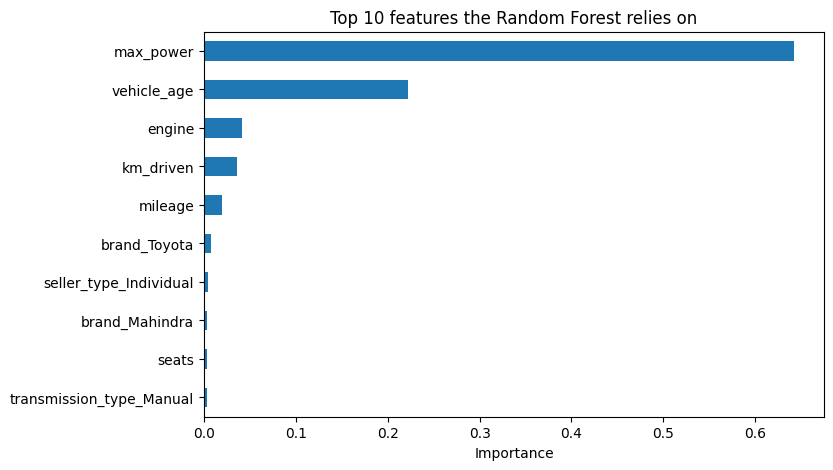

In [ ]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

importance = pd.Series(rf.feature_importances_, index=X_train.columns)
top = importance.sort_values(ascending=False).head(10)

print(top.round(3))

top.sort_values().plot(kind='barh', figsize=(8, 5))
plt.title("Top 10 features the Random Forest relies on")
plt.xlabel("Importance")
plt.show()

In [ ]:
import os
import joblib

joblib.dump(rf, 'car_price_model.pkl', compress=3)
joblib.dump(list(X_train.columns), 'model_columns.pkl')

print("Model size (MB):", round(os.path.getsize('car_price_model.pkl') / 1_000_000, 1))
print("Number of columns saved:", len(X_train.columns))

Model size (MB): 23.6
Number of columns saved: 43


In [ ]:
import json
import sklearn
from google.colab import files

options = {
    "brand": sorted(d["brand"].unique().tolist()),
    "fuel_type": sorted(d["fuel_type"].unique().tolist()),
    "transmission_type": sorted(d["transmission_type"].unique().tolist()),
    "seller_type": sorted(d["seller_type"].unique().tolist()),
    "seats": sorted(int(s) for s in d["seats"].unique()),
}

with open("options.json", "w") as f:
    json.dump(options, f)

print("scikit-learn version:", sklearn.__version__)
print(options)

for name in ["car_price_model.pkl", "model_columns.pkl", "options.json"]:
    files.download(name)

scikit-learn version: 1.6.1
{'brand': ['Audi', 'BMW', 'Bentley', 'Datsun', 'Ferrari', 'Force', 'Ford', 'Honda', 'Hyundai', 'Isuzu', 'Jaguar', 'Jeep', 'Kia', 'Land Rover', 'Lexus', 'MG', 'Mahindra', 'Maruti', 'Maserati', 'Mercedes-AMG', 'Mercedes-Benz', 'Mini', 'Nissan', 'Porsche', 'Renault', 'Rolls-Royce', 'Skoda', 'Tata', 'Toyota', 'Volkswagen', 'Volvo'], 'fuel_type': ['CNG', 'Diesel', 'Electric', 'LPG', 'Petrol'], 'transmission_type': ['Automatic', 'Manual'], 'seller_type': ['Dealer', 'Individual', 'Trustmark Dealer'], 'seats': [0, 2, 4, 5, 6, 7, 8, 9]}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sklearn
print(sklearn.__version__)

1.6.1


In [54]:
bentley = d[d['brand'] == 'Bentley']
print(len(bentley))
print(bentley[['vehicle_age', 'km_driven', 'engine', 'max_power', 'selling_price']])

3
       vehicle_age  km_driven  engine  max_power  selling_price
1172             9       9000    5998      626.0       14500000
10040            9      37500    5998      600.0        5200000
12997           10      30000    5998      552.0        8100000


In [55]:
pred_log = rf.predict(X_test)
pred = np.expm1(pred_log)
actual = np.expm1(y_test)

results = pd.DataFrame({'actual': actual.values, 'predicted': pred})
results['error'] = (results['actual'] - results['predicted']).abs()

bands = [0, 300000, 600000, 1000000, 2000000, 100000000]
labels = ['under 3L', '3-6L', '6-10L', '10-20L', 'above 20L']
results['band'] = pd.cut(results['actual'], bins=bands, labels=labels)

summary = results.groupby('band', observed=True).agg(cars=('error', 'count'), MAE=('error', 'mean'))
print(summary.round(0))

           cars       MAE
band                     
under 3L    427   39693.0
3-6L       1210   55579.0
6-10L       885   83233.0
10-20L      360  178744.0
above 20L   161  670268.0


In [56]:
print(len(results))
print(results['band'].isna().sum())

3043
0


In [57]:
print(len(df))
print(len(d))
print(len(X))
print(len(X_test))

15411
15211
15211
3043
